# EMQA_L7_decision

**Cost-loss rule: act when the spike probability exceeds C/L**

Energy Markets Quantitative Analysis (EMQA), Lecture 7 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L7/EMQA_L7_decision/EMQA_L7_decision.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

Value over the test year (thousand EUR per MW of flexible load) of moving 1 MWh out of every hour in which the XGBoost spike probability exceeds an action threshold, against the threshold, with the cost-loss threshold C/L (C = 30 EUR/MWh, assumed; L = mean excess over the spike threshold in the validation year) and 0.5. Romanian day-ahead prices, test year 2025-11-01 to 2026-10-31. Data: test year 2025-11-01 to 2026-10-31; 1 MW of flexible load. Source: energy-charts.info (Fraunhofer ISE); Yahoo Finance (EUA).

The numbers printed at the end are those on the slide of Lecture 7.

## Setup: chart style and helpers

In [2]:
import io
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    "figure.facecolor": "none", "axes.facecolor": "none", "savefig.transparent": True,
    "axes.grid": False, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#222222", "axes.labelcolor": "#222222", "xtick.color": "#222222", "ytick.color": "#222222",
    "text.color": "#222222", "font.size": 11, "axes.titlesize": 11.5, "axes.labelsize": 11,
    "legend.fontsize": 10.5, "legend.frameon": False, "lines.linewidth": 1.4, "font.family": "DejaVu Sans"})
PAL = {"RO": "#2a78d6", "DE_LU": "#eb6834", "HU": "#1baf7a", "BG": "#eda100",
       "c5": "#e87ba4", "c6": "#008300", "c7": "#6250d6", "c8": "#e34948"}


def legend_bottom(fig, handles=None, labels=None, ncol=4):
    """Legend centred under the axes, outside the plotting area (save_chart moves it just below the lowest axis label)."""
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for hh, ll in zip(*ax.get_legend_handles_labels()):
                if ll not in labels:
                    handles.append(hh)
                    labels.append(ll)
    if handles:
        fig.legend(handles, labels, loc="upper center", ncol=ncol, frameon=False, handlelength=1.6, handletextpad=0.5,
                   columnspacing=1.0, borderaxespad=0.1)


def save_chart(fig, name, bottom=None):
    """The axes use the whole figure height; the legend (if any) goes just below the lowest axis label."""
    fig.tight_layout(pad=0.3)
    if fig.legends:
        fig.canvas.draw()
        r = fig.canvas.get_renderer()
        y0 = min(ax.get_tightbbox(r).y0 for ax in fig.axes) / fig.bbox.height
        fig.legends[0].set_loc("upper center")
        fig.legends[0].set_bbox_to_anchor((0.5, y0 - 0.01), transform=fig.transFigure)
    plt.savefig(name + ".png", dpi=150, bbox_inches="tight", pad_inches=0.03, transparent=True)
    plt.show()


def show(label, value, fmt=""):
    """Print a number that appears on the slide."""
    print(f"{label}: {format(value, fmt)}")

## Data: Romanian day-ahead prices, CET delivery day x 24 hours

In [3]:
TZ = "Europe/Brussels"


def day_matrix(s):
    """UTC-indexed hourly series -> CET delivery day x 24 hours (Assignment 1 / epftoolbox DST convention) + DST flag."""
    s = s.copy()
    s.index = pd.to_datetime(s.index, utc=True).tz_convert(TZ)
    df = pd.DataFrame({"v": s.values, "day": s.index.tz_localize(None).normalize(), "h": s.index.hour})
    m = df.groupby(["day", "h"])["v"].mean().unstack("h").reindex(columns=range(24))     # 25-h day: doubled hour averaged
    days = m.index
    nh = ((((days + pd.Timedelta(days=1)).tz_localize(TZ)) - days.tz_localize(TZ)) / pd.Timedelta(hours=1)).astype(int)
    dst = pd.Series(np.asarray(nh != 24), index=days)
    for dd in days[dst.values]:
        if pd.isna(m.loc[dd, 2]):
            m.loc[dd, 2] = 0.5 * (m.loc[dd, 1] + m.loc[dd, 3])                              # 23-h day: h02 = mean(h01, h03)
    m = m.dropna(how="any")
    return m, dst.reindex(m.index)


# Romanian day-ahead price (OPCOM PZU), hourly; after 1 Oct 2025 the hour is the mean of its four quarter-hours
HP = pd.read_csv(DATA + "power_da_prices_hourly_utc.csv", usecols=["timestamp_utc", "RO"], index_col=0)
PM_ALL, DST = day_matrix(HP["RO"].dropna())          # all CET delivery days since 2015 x 24 hours
# sample of the lecture: 2022-01-01 to the cut-off 2026-10-31 (last complete month at the download of 2026-11-04)
START, END = pd.Timestamp("2022-01-01"), pd.Timestamp("2026-10-31")
CAL = pd.date_range(START, END, freq="D")
PM = PM_ALL.reindex(CAL)
assert not PM.isna().any().any(), "panel has gaps"
P_ = PM.values.astype(float)
DOW = CAL.dayofweek.values
IDX = {t: i for i, t in enumerate(CAL)}
FIRST = 7                                             # first usable target row (needs the price of d-7)
TEST0 = END - pd.Timedelta(days=364)                  # test year = the last 365 days (as in Lecture 2)
VAL0 = TEST0 - pd.Timedelta(days=365)                 # validation year = the 365 days before it
TDAYS = pd.date_range(TEST0, END, freq="D")
VDAYS = pd.date_range(VAL0, TEST0 - pd.Timedelta(days=1), freq="D")
rows_all = np.array([IDX[t] for t in TDAYS])
A = P_[rows_all]                                      # actual prices of the test year (365 days x 24 hours), EUR/MWh
print("panel", CAL[0].date(), "to", CAL[-1].date(), "| test year", TEST0.date(), "to", END.date(), A.shape)

panel 2022-01-01 to 2026-10-31 | test year 2025-11-01 to 2026-10-31 (365, 24)


## Model outputs: saved, or recomputed with `RUN_ALL = True`

The models of this chart take about 30 minutes on one core (12 monthly refits of the spike classifiers) to refit, more than a free Colab session allows. With `RUN_ALL = False` the notebook loads their saved outputs (`decision_results.npz`, produced by `lectures/L7/analysis_L7.py`); with `RUN_ALL = True` it recomputes them from the data with the code below, which is the code of the lecture.

In [4]:
RUN_ALL = False      # True: recompute the model outputs from the data (needs torch, xgboost, scikit-learn)

Code of the models (copied from `lectures/L7/analysis_L7.py`); defining the functions takes no time.

In [5]:
import os
import time

# constants of lectures/L7/analysis_L7.py
SEED = 20261106
PLAGS, XLAGS = (1, 2, 3, 7), (2, 3, 7)            # price lags (days) and lags of load, wind+solar (>= 2 days)
XGB_NAMES = ['P(d-1,h)', 'P(d-2,h)', 'P(d-3,h)', 'P(d-7,h)', 'P(d-1,23)', 'min P(d-1)', 'max P(d-1)', 'mean P(d-1)', 'L(d-2,h)', 'L(d-7,h)', 'RES(d-2,h)', 'RES(d-7,h)', 'mean L(d-2)', 'mean RES(d-2)', 'hydro(d-2)', 'nuclear(d-2)', 'net imports(d-2)', 'EUA(d-2)', 'hour', 'day of week']
# configurations chosen by random search on the validation year (Quantlet EMQA_L7_search)
CFG_DNN = {'n1': 512, 'n2': 0, 'act': 'softplus', 'drop': 0.1, 'lr': 0.0003, 'wd': 1e-05, 'l1': 0.0, 'batch': 64, 'load': True, 'res': True, 'fund': True, 'p3': True}
CFG_XGB = {'n_est': 1500, 'eta': 0.02, 'depth': 8, 'mcw': 5, 'sub': 0.8, 'col': 1.0, 'lam': 0.1, 'obj': 'reg:absoluteerror'}
THR_Q = 0.90
CLF_NAMES = XGB_NAMES + ["threshold"]
CLF_CFG = {'n_est': 400, 'eta': 0.05, 'depth': 4, 'mcw': 20, 'sub': 0.8, 'col': 0.8, 'lam': 1.0}


def shift_rows(A, k):
    out = np.full_like(A, np.nan)
    out[k:] = A[:-k]
    return out


def mad_scale(x):
    x = np.asarray(x, float).ravel()
    m = np.median(x)
    s = stats.median_abs_deviation(x, scale="normal")
    return m, (s if s > 0 else 1.0)


def blocks_of(days, freq="M"):
    """(first row, last row) of each calendar month (or quarter) of a day range."""
    out = []
    for _, g in pd.Series(days, index=days).groupby(days.to_period(freq)):
        out.append((IDX[g.index[0]], IDX[g.index[-1]]))
    return out


def gbm_rows(Pa, La, Ra, Fa, rows, leak=False):
    """Long-format features for (day, hour) pairs (the 20 features of the L2 GBM). leak=True adds the realised load and
    wind+solar of the delivery hour itself (NOT known at gate closure: used only to measure the look-ahead pitfall)."""
    P1, P2, P3, P7 = (shift_rows(Pa, k) for k in PLAGS)
    L2_, L7_, R2_, R7_ = shift_rows(La, 2), shift_rows(La, 7), shift_rows(Ra, 2), shift_rows(Ra, 7)
    feats = []
    for h in range(24):
        f = [P1[rows, h], P2[rows, h], P3[rows, h], P7[rows, h], P1[rows, 23], P1[rows].min(1), P1[rows].max(1),
             P1[rows].mean(1), L2_[rows, h], L7_[rows, h], R2_[rows, h], R7_[rows, h], L2_[rows].mean(1),
             R2_[rows].mean(1), Fa[rows], np.full(len(rows), h), DOW[rows]]
        if leak:
            f += [La[rows, h], Ra[rows, h]]
        feats.append(np.column_stack(f))
    return np.stack(feats, 1)


def _xgb(cfg, seed):
    import xgboost as xgb
    return xgb.XGBRegressor(n_estimators=cfg["n_est"], learning_rate=cfg["eta"], max_depth=cfg["depth"],
                            min_child_weight=cfg["mcw"], subsample=cfg["sub"], colsample_bytree=cfg["col"],
                            reg_lambda=cfg["lam"], objective=cfg["obj"], tree_method="hist", n_jobs=1, random_state=seed,
                            max_leaves=cfg.get("leaves", 0), grow_policy=cfg.get("grow", "depthwise"))


def xgb_block(Pa, La, Ra, Fa, i0, i1, cfg, seed=SEED, lo=FIRST, leak=False, shap=False):
    """Fit on target rows lo..i0-1, forecast rows i0..i1. Target = asinh((P-m)/s), m and s from the training prices."""
    t0 = time.perf_counter()
    tr = np.arange(lo, i0)
    m, s = mad_scale(Pa[tr])
    p = len(XGB_NAMES) + (2 if leak else 0)
    Xtr = gbm_rows(Pa, La, Ra, Fa, tr, leak).reshape(-1, p)
    ytr = np.arcsinh((Pa[tr] - m) / s).ravel()
    mdl = _xgb(cfg, seed).fit(Xtr, ytr)
    te = np.arange(i0, i1 + 1)
    Xte = gbm_rows(Pa, La, Ra, Fa, te, leak).reshape(-1, p)
    y = mdl.predict(Xte).reshape(len(te), 24)
    out = {"pred": m + s * np.sinh(y), "sec": time.perf_counter() - t0}
    if shap:
        import xgboost as xgb
        con = mdl.get_booster().predict(xgb.DMatrix(Xte), pred_contribs=True)      # exact SHAP values (Lundberg et al. 2020)
        out.update({"shap": con.reshape(len(te), 24, p + 1), "m": m, "s": s, "X": Xte.reshape(len(te), 24, p)})
    return out


def spike_threshold(t):
    """Spike threshold for delivery days of the month starting at t: 90th percentile of the hourly prices of the 365 days before t."""
    w = PM_ALL.loc[t - pd.Timedelta(days=365):t - pd.Timedelta(days=1)].values.ravel()
    return float(np.quantile(w, THR_Q))


def clf_rows(Pa, La, Ra, Fa, rows, theta):
    X = gbm_rows(Pa, La, Ra, Fa, rows)
    th = np.repeat(theta[rows][:, None, None], 24, 1)
    return np.concatenate([X, th], 2)


def clf_block(Pa, La, Ra, Fa, theta, i0, i1, event, seed=SEED):
    """P(event) for rows i0..i1; event = 'spike' (price > threshold of its month) or 'neg' (price <= 0).
    XGBoost and a logistic regression (standardised features, one-hot hour and weekday), fitted on rows before the month."""
    import xgboost as xgb
    from sklearn.linear_model import LogisticRegression
    tr = np.arange(FIRST, i0)
    te = np.arange(i0, i1 + 1)
    Xtr, Xte = clf_rows(Pa, La, Ra, Fa, tr, theta).reshape(-1, len(CLF_NAMES)), clf_rows(Pa, La, Ra, Fa, te, theta).reshape(-1, len(CLF_NAMES))
    lab = (lambda r: (Pa[r] > theta[r][:, None])) if event == "spike" else (lambda r: (Pa[r] <= 0))
    ytr = lab(tr).ravel().astype(int)
    c = CLF_CFG
    mdl = xgb.XGBClassifier(n_estimators=c["n_est"], learning_rate=c["eta"], max_depth=c["depth"], min_child_weight=c["mcw"],
                            subsample=c["sub"], colsample_bytree=c["col"], reg_lambda=c["lam"], tree_method="hist", n_jobs=1,
                            random_state=seed, objective="binary:logistic").fit(Xtr, ytr)
    px = mdl.predict_proba(Xte)[:, 1].reshape(len(te), 24)

    def lin(X):
        num = np.delete(X, [18, 19], 1)
        return num, np.column_stack([np.eye(24)[X[:, 18].astype(int)], np.eye(7)[X[:, 19].astype(int)]])
    ntr, dtr = lin(Xtr)
    nte, dte = lin(Xte)
    mu, sg = ntr.mean(0), ntr.std(0)
    sg[sg == 0] = 1
    lr = LogisticRegression(C=1.0, max_iter=3000).fit(np.column_stack([(ntr - mu) / sg, dtr]), ytr)
    pl = lr.predict_proba(np.column_stack([(nte - mu) / sg, dte]))[:, 1].reshape(len(te), 24)
    return {"xgb": px, "logit": pl, "share_train": float(ytr.mean())}


QL = "EMQA_L7_decision"


def load_results(fname):
    """Saved outputs of the full computation, stored in this Quantlet folder (local copy, else the public repository)."""
    if os.path.isfile(fname):
        return dict(np.load(fname, allow_pickle=False))
    raw = urllib.request.urlopen(REPO + "Quantlets/L7/" + QL + "/" + fname).read()
    return dict(np.load(io.BytesIO(raw), allow_pickle=False))

In [6]:
if RUN_ALL:
    # ---- full information set at gate closure (12:00 CET on d-1), as in lectures/L7/analysis_L7.py
    from joblib import Parallel, delayed
    GH = pd.read_csv(DATA + "generation_ro_mw_hourly_utc.csv", index_col=0)
    LM, _ = day_matrix(GH["load"].dropna())
    RM, _ = day_matrix((GH["wind_onshore"] + GH["solar"]).dropna())
    L_, R_ = LM.reindex(CAL).values.astype(float), RM.reindex(CAL).values.astype(float)
    G = pd.read_csv(DATA + "generation_ro_mw_daily_cet.csv", parse_dates=["date_cet"]).set_index("date_cet")
    CB = pd.read_csv(DATA + "crossborder_ro_mw_daily_cet.csv", parse_dates=["date_cet"]).set_index("date_cet")
    EUA = pd.read_csv(DATA + "eua_daily.csv", parse_dates=["date"]).set_index("date")["eua_etc_co2l_eur_per_unit"]
    CAL_EX = pd.date_range(START - pd.Timedelta(days=30), END, freq="D")
    FUND_RAW = pd.DataFrame({"hydro": (G["hydro_run_of_river"] + G["hydro_water_reservoir"]).reindex(CAL_EX),
                             "nuclear": G["nuclear"].reindex(CAL_EX), "netimp": CB["sum"].reindex(CAL_EX), "eua": EUA.reindex(CAL_EX)})
    F_ = FUND_RAW.ffill().shift(2).reindex(CAL).values.astype(float)      # past only, lagged 2 days
    MB = blocks_of(TDAYS, "M")                                           # 12 monthly refits in the test year
    _vm = blocks_of(VDAYS, "M")
    VB = [(_vm[k][0], _vm[k + 2][1]) for k in range(0, 12, 3)]           # validation year: 4 quarterly refits
    FC = {}
    MONTH_START = {}
    for _t in CAL:
        MONTH_START.setdefault(_t.to_period("M"), _t.replace(day=1))
    THETA = np.array([spike_threshold(MONTH_START[t.to_period("M")]) for t in CAL])
    res_sp = Parallel(n_jobs=-1)(delayed(clf_block)(P_, L_, R_, F_, THETA, a, b, "spike") for a, b in MB)
    FC["spike_xgb"], FC["spike_logit"] = np.vstack([r["xgb"] for r in res_sp]), np.vstack([r["logit"] for r in res_sp])
else:
    FC = load_results("decision_results.npz")
    assert list(FC.get("days", TDAYS.strftime("%Y-%m-%d"))) == list(TDAYS.strftime("%Y-%m-%d"))
print(sorted(k for k in FC if k != "days"))

['spike_logit', 'spike_xgb']


## Value of acting, by threshold

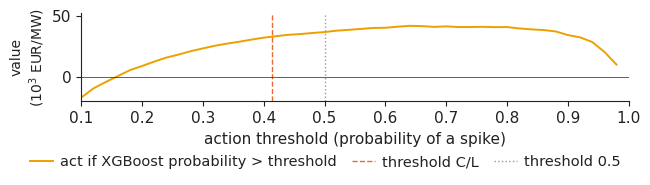

In [7]:
THR_Q = 0.90


def spike_threshold(t):
    """Spike threshold for delivery days of the month starting at t: 90th percentile of the hourly prices of the 365 days before t."""
    w = PM_ALL.loc[t - pd.Timedelta(days=365):t - pd.Timedelta(days=1)].values.ravel()
    return float(np.quantile(w, THR_Q))


_TH = {}


def theta_of(t):
    """threshold of the delivery month of day t (known at the start of the month)"""
    ms = t.replace(day=1)
    if ms not in _TH:
        _TH[ms] = spike_threshold(ms)
    return _TH[ms]


TH_T = np.array([theta_of(t) for t in TDAYS])
Y_SP = (A > TH_T[:, None]).astype(int)                # spike hours of the test year
Y_NG = (A <= 0).astype(int)                           # hours with price <= 0

# cost-loss rule: C = assumed cost of acting; L-bar = mean excess over the threshold in spike hours of the VALIDATION year
C_ACT = 30.0
vrows = np.array([IDX[t] for t in VDAYS])
PV, THV = P_[vrows], np.array([theta_of(t) for t in VDAYS])[:, None]
LBAR = float((PV - THV)[PV > THV].mean())
CUT = C_ACT / LBAR
VALUE = A - TH_T[:, None] - C_ACT                                   # gain of moving 1 MWh out of the hour, EUR


def act_value(pi, cut):
    return float(VALUE[pi > cut].sum())


past = np.stack([P_[rows_all - k] for k in range(1, 8)], 0)
persist = (past > TH_T[None, :, None]).mean(0)
CUTS = np.linspace(0.02, 0.98, 49)
VCURVE = np.array([act_value(FC["spike_xgb"], c) for c in CUTS]) / 1000
fig, ax = plt.subplots(figsize=(6.4, 1.45))
ax.plot(CUTS, VCURVE, color=PAL["BG"], label="act if XGBoost probability > threshold")
ax.axvline(CUT, color=PAL["DE_LU"], ls="--", lw=1.0, label="threshold C/L")
ax.axvline(0.5, color="#9a9a9a", ls=":", lw=1.0, label="threshold 0.5")
ax.set_xlim(0.1, 1.0)
ax.set_ylim(min(0, VCURVE[CUTS >= 0.1].min()) - 3, VCURVE.max() * 1.25)
ax.axhline(0, color="#222222", lw=0.5)
ax.set_xlabel("action threshold (probability of a spike)")
ax.set_ylabel("value\n(10$^3$ EUR/MW)", fontsize=10)
legend_bottom(fig, ncol=3)
save_chart(fig, "decision", bottom=0.22)

## Numbers on the slide

In [8]:
show('Mean loss of a missed spike L, EUR/MWh', LBAR, '.1f')
show('Cost-loss threshold C/L', CUT, '.3f')
show('Value at C/L, thousand EUR per MW', act_value(FC['spike_xgb'], CUT) / 1000, '.1f')
show('Value at 0.5', act_value(FC['spike_xgb'], 0.5) / 1000, '.1f')
show('Value with persistence at C/L', act_value(persist, CUT) / 1000, '.1f')
show('Value with the logistic classifier at C/L', act_value(FC['spike_logit'], CUT) / 1000, '.1f')
show('Value with perfect foresight', VALUE[VALUE > 0].sum() / 1000, '.1f')
show('Alerts at C/L (hours)', int((FC['spike_xgb'] > CUT).sum()), 'd')
show('Best threshold seen afterwards', CUTS[np.argmax(VCURVE)], '.2f')

Mean loss of a missed spike L, EUR/MWh: 72.5
Cost-loss threshold C/L: 0.414
Value at C/L, thousand EUR per MW: 33.0
Value at 0.5: 36.7
Value with persistence at C/L: 11.8
Value with the logistic classifier at C/L: 34.2
Value with perfect foresight: 62.4
Alerts at C/L (hours): 1806
Best threshold seen afterwards: 0.64
